## import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import torchvision.models as models
from sqlalchemy import create_engine, text
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
import numpy as np
import os
import io
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# --- Training Loop Consts ---
epoch_count = 60
best_val_accuracy = 0.0
patience_early_stop = 12
patience_counter = 0
model_save_path = "best_resnet18_model_from_scratch.pth"


In [2]:
def create_resnet18_for_9_channels(num_classes=5):
    """
    Creates a ResNet18 model from scratch and adapts it for 9-channel input images.
    The model is initialized with random weights, not pre-trained ones.
    """
    # 1. Load a ResNet18 model without pre-trained weights
    # By setting weights=None, the model is initialized "from scratch".
    model = models.resnet18(weights=None)

    # 2. Adapt the first convolutional layer for 9 input channels
    # The original layer is model.conv1
    original_conv1 = model.conv1
    
    # Create a new Conv2d layer with 9 input channels.
    # It will be initialized with random weights by default.
    new_conv1 = nn.Conv2d(
        in_channels=9,
        out_channels=original_conv1.out_channels, # Keep the same number of output filters (64)
        kernel_size=original_conv1.kernel_size,
        stride=original_conv1.stride,
        padding=original_conv1.padding,
        bias=original_conv1.bias is not None
    )

    # Replace the original conv1 layer with our new one
    model.conv1 = new_conv1

    # 3. Adapt the final fully connected layer for our number of classes
    num_ftrs = model.fc.in_features
    model.fc = nn.Linear(num_ftrs, num_classes)

    print(f"ResNet18 model created from scratch. First conv layer adapted for 9 channels, final layer adapted for {num_classes} classes.")
    return model

In [3]:
# --- Helper function and Dataset Class ---
def get_initial_records_and_map(db_url_str):
    engine = create_engine(db_url_str)
    all_records_from_db, label_map, train_records_list, val_records_list = [], {}, [], []
    try:
        with engine.connect() as conn:
            result = conn.execute(text("SELECT id, surface_group FROM final_balanced_trail_segments WHERE image_data IS NOT NULL AND surface_group IS NOT NULL"))
            all_records_from_db = result.fetchall()
        if not all_records_from_db: return [], [], {}
        unique_labels = sorted(list(set(r[1] for r in all_records_from_db)))
        label_map = {label: idx for idx, label in enumerate(unique_labels)}
        all_records_with_labels = [(r[0], label_map[r[1]]) for r in all_records_from_db]
        train_records_list, val_records_list = train_test_split(
            all_records_with_labels, test_size=0.2, random_state=42,
            stratify=[r[1] for r in all_records_with_labels] if len(all_records_with_labels) > 1 else None
        )
        print(f"Pre-fetched data: {len(train_records_list)} train, {len(val_records_list)} val records. Label map size: {len(label_map)}")
    except Exception as e: print(f"Error during initial data fetch: {e}")
    finally:
        if engine: engine.dispose()
    return train_records_list, val_records_list, label_map

class TrailSegmentDataset(Dataset):
    def __init__(self, db_url, records_list, label_map, transform=None, for_stats_calc=False):
        self.db_url, self.engine, self.records, self.label_map, self.transform, self.for_stats_calc = \
            db_url, None, records_list, label_map, transform, for_stats_calc
    def _get_engine(self):
        if self.engine is None: self.engine = create_engine(self.db_url)
        return self.engine
    def __len__(self): return len(self.records)
    def __getitem__(self, idx):
        seg_id, label = self.records[idx]
        try:
            with self._get_engine().connect() as conn:
                res = conn.execute(text("SELECT image_data FROM final_balanced_trail_segments WHERE id = :id"), {"id": seg_id})
                image_bytes = res.scalar()
            if image_bytes is None: return (None, label) if self.for_stats_calc else (_ for _ in ()).throw(ValueError(f"Img None for id {seg_id}"))
            image_array = np.load(io.BytesIO(image_bytes)).astype(np.float32)
            return (self.transform(image_array) if self.transform else image_array), label
        except Exception as e:
            print(f"Error in __getitem__ for seg_id {seg_id}: {e}")
            return (None, label) if self.for_stats_calc else (_ for _ in ()).throw(e)


In [4]:
# --- Main Data Preparation ---
db_url = "postgresql://markfinlay:@localhost:5432/osm"

train_img_records, val_img_records, global_label_map = get_initial_records_and_map(db_url)

# --- Normalization Calculation ---
print("Calculating mean and std for normalization...")
temp_train_dataset = TrailSegmentDataset(db_url, train_img_records, global_label_map, for_stats_calc=True)
all_imgs = [img for img, _ in temp_train_dataset if img is not None]
all_imgs_np = np.stack(all_imgs, axis=0)
channel_means = np.mean(all_imgs_np, axis=(0, 1, 2))
channel_stds = np.std(all_imgs_np, axis=(0, 1, 2))
channel_stds = np.maximum(channel_stds, 1e-6)
print(f"Means: {channel_means.tolist()}\nStds: {channel_stds.tolist()}")

# --- Transforms and DataLoaders ---
train_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=channel_means.tolist(), std=channel_stds.tolist()),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
])
val_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=channel_means.tolist(), std=channel_stds.tolist()),
])

train_dataset = TrailSegmentDataset(db_url, train_img_records, global_label_map, transform=train_transform)
val_dataset = TrailSegmentDataset(db_url, val_img_records, global_label_map, transform=val_transform)

num_workers = 0
pin_memory = False
if torch.cuda.is_available(): pin_memory = True

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=num_workers, pin_memory=pin_memory)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=num_workers, pin_memory=pin_memory) if val_dataset else None

Pre-fetched data: 97712 train, 24428 val records. Label map size: 5
Calculating mean and std for normalization...
Means: [0.27138757705688477, 0.26496562361717224, 0.2413945496082306, 0.04870079085230827, 0.08920029550790787, 0.10534325987100601, 0.06740844994783401, 0.044062789529561996, 0.1676764339208603]
Stds: [0.6514589190483093, 0.6197359561920166, 0.6532068252563477, 0.08828247338533401, 0.13207246363162994, 0.16663502156734467, 0.09176772087812424, 0.06117460876703262, 0.4094831347465515]


In [5]:
# --- Setup for Training ---
device = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

num_classes = len(global_label_map)
# Use the updated function to create the model from scratch
model = create_resnet18_for_9_channels(num_classes).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)

# Class weights
from collections import Counter, defaultdict # Import defaultdict
train_labels = [label for _, label in train_img_records]
counts = Counter(train_labels)
total = sum(counts.values())
weights = torch.tensor([total / (num_classes * counts.get(i, 1)) for i in range(num_classes)], dtype=torch.float).to(device)
criterion = nn.CrossEntropyLoss(weight=weights)

# Learning Rate Scheduler
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=5)

# history tracking
history = defaultdict(list)

print("--- Starting ResNet18 Training From Scratch ---")
for epoch in range(epoch_count):
    model.train()
    running_loss, train_correct, train_total = 0.0, 0, 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
        train_correct += (outputs.argmax(dim=1) == labels).sum().item()
        train_total += labels.size(0)

    epoch_loss = running_loss / train_total
    epoch_train_accuracy = 100 * train_correct / train_total
    print(f"Epoch [{epoch+1}/{epoch_count}] - Train Loss: {epoch_loss:.4f}, Train Acc: {epoch_train_accuracy:.2f}%")

    # Record training metrics
    history['train_loss'].append(epoch_loss)
    history['train_acc'].append(epoch_train_accuracy)

    if val_loader:
        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                val_loss += criterion(outputs, labels).item() * images.size(0)
                val_correct += (outputs.argmax(dim=1) == labels).sum().item()
                val_total += labels.size(0)

        epoch_val_loss = val_loss / val_total
        epoch_val_accuracy = 100 * val_correct / val_total
        print(f"→ Validation Loss: {epoch_val_loss:.4f}, Validation Acc: {epoch_val_accuracy:.2f}%")

        # Record validation metrics
        history['val_loss'].append(epoch_val_loss)
        history['val_acc'].append(epoch_val_accuracy)

        # Scheduler step
        scheduler.step(epoch_val_loss)

        if epoch_val_accuracy > best_val_accuracy:
            best_val_accuracy = epoch_val_accuracy
            patience_counter = 0
            torch.save(model.state_dict(), model_save_path)
            print(f"✓ Saved new best model to {model_save_path} with accuracy: {best_val_accuracy:.2f}%")
        else:
            patience_counter += 1

        if patience_counter >= patience_early_stop:
            print(f"Early stopping triggered after {patience_early_stop} epochs of no improvement.")
            break
print("--- Training complete ---")

Using device: mps
ResNet18 model created from scratch. First conv layer adapted for 9 channels, final layer adapted for 5 classes.
--- Starting ResNet18 Training From Scratch ---
Epoch [1/60] - Train Loss: 1.4153, Train Acc: 36.74%
→ Validation Loss: 1.4393, Validation Acc: 37.80%
✓ Saved new best model to best_resnet18_model_from_scratch.pth with accuracy: 37.80%
Epoch [2/60] - Train Loss: 1.3688, Train Acc: 39.47%
→ Validation Loss: 1.3194, Validation Acc: 41.90%
✓ Saved new best model to best_resnet18_model_from_scratch.pth with accuracy: 41.90%
Epoch [3/60] - Train Loss: 1.3428, Train Acc: 40.67%
→ Validation Loss: 1.3240, Validation Acc: 41.44%
Epoch [4/60] - Train Loss: 1.3261, Train Acc: 41.88%
→ Validation Loss: 1.3233, Validation Acc: 41.32%
Epoch [5/60] - Train Loss: 1.3153, Train Acc: 42.45%
→ Validation Loss: 1.2995, Validation Acc: 42.66%
✓ Saved new best model to best_resnet18_model_from_scratch.pth with accuracy: 42.66%
Epoch [6/60] - Train Loss: 1.3072, Train Acc: 43.00

In [6]:
# --- Save History to JSON ---
import json
history_save_path = "resnet18_scratch_training_history.json"
history_dict = dict(history)
with open(history_save_path, 'w') as f:
    json.dump(history_dict, f, indent=4)

print(f"Training history saved to {history_save_path}")

Training history saved to resnet18_scratch_training_history.json


Confusion matrix plot saved to 'resnet18_scratch_training_history.png'


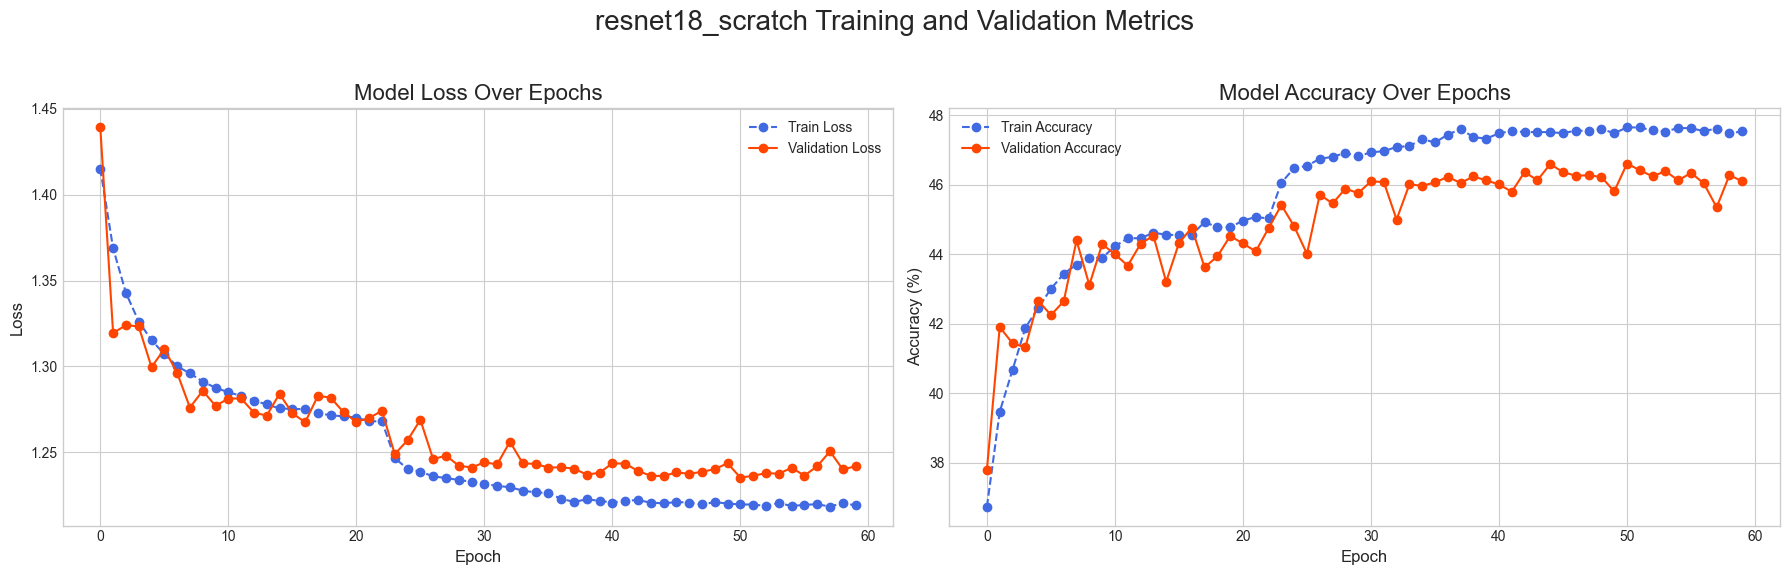

In [7]:
# --- Plotting Training History ---
plt.style.use('seaborn-v0_8-whitegrid')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

# Plot 1: Model Loss
ax1.plot(history['train_loss'], label='Train Loss', color='royalblue', marker='o', linestyle='--')
ax1.plot(history['val_loss'], label='Validation Loss', color='orangered', marker='o', linestyle='-')
ax1.set_title('Model Loss Over Epochs', fontsize=16)
ax1.set_xlabel('Epoch', fontsize=12)
ax1.set_ylabel('Loss', fontsize=12)
ax1.legend()
ax1.grid(True)

# Plot 2: Model Accuracy
ax2.plot(history['train_acc'], label='Train Accuracy', color='royalblue', marker='o', linestyle='--')
ax2.plot(history['val_acc'], label='Validation Accuracy', color='orangered', marker='o', linestyle='-')
ax2.set_title('Model Accuracy Over Epochs', fontsize=16)
ax2.set_xlabel('Epoch', fontsize=12)
ax2.set_ylabel('Accuracy (%)', fontsize=12)
ax2.legend()
ax2.grid(True)

plt.suptitle('resnet18_scratch Training and Validation Metrics', fontsize=20)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])

# Save and show the figure
output_filename = "resnet18_scratch_training_history.png"
plt.savefig(output_filename, dpi=300)
print(f"Confusion matrix plot saved to '{output_filename}'")
plt.show()

ResNet18 model created from scratch. First conv layer adapted for 9 channels, final layer adapted for 5 classes.
Generating confusion matrix...
Confusion matrix plot saved to 'resnet18_scratch_confusion_matrix.png'


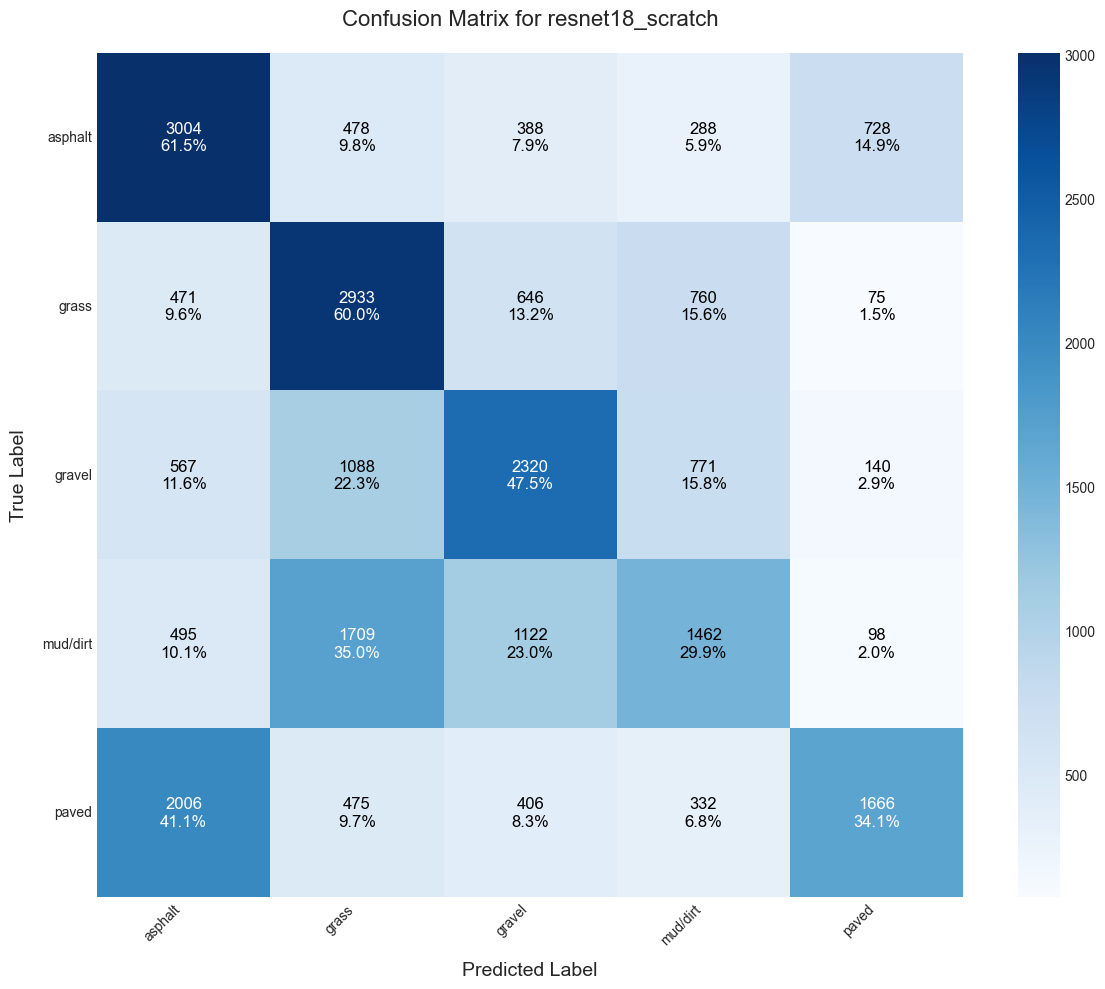

In [8]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import torch

# 1. Initialize and load the best model
# Ensure the model architecture is defined and pass the number of classes
model = create_resnet18_for_9_channels(num_classes=len(global_label_map))
# Load the state dictionary from your saved model file
model.load_state_dict(torch.load(model_save_path, map_location=device))
# Move the model to the appropriate device (GPU/CPU)
model.to(device)
# Set the model to evaluation mode
model.eval()

# 2. Get predictions on the validation set
all_labels = []
all_preds = []

with torch.no_grad():
    for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        preds = torch.argmax(outputs, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# 4. COMPUTE AND PLOT CONFUSION MATRIX
print("Generating confusion matrix...")
cm = confusion_matrix(all_labels, all_preds)
class_names = [item[0] for item in sorted(global_label_map.items(), key=lambda item: item[1])]

plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(cm, annot=False, fmt='d', cmap='Blues', ax=ax, xticklabels=class_names, yticklabels=class_names)

# Add annotations (counts and percentages for each true label)
for i in range(len(class_names)):
    for j in range(len(class_names)):
        count = cm[i, j]
        row_sum = np.sum(cm[i])
        percentage = f"{(count / row_sum) * 100:0.1f}%" if row_sum > 0 else "0.0%"
        text_annotation = f"{count}\n{percentage}"
        # Use a contrasting color for text if the background is dark
        text_color = "white" if cm[i, j] > (cm.max() / 2) else "black"
        ax.text(j + 0.5, i + 0.5, text_annotation, ha='center', va='center', color=text_color, fontsize=12)

ax.set_xlabel('Predicted Label', fontsize=14, labelpad=10)
ax.set_ylabel('True Label', fontsize=14, labelpad=10)
ax.set_title('Confusion Matrix for resnet18_scratch', fontsize=16, pad=20)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()

# Save and show the figure
output_filename = "resnet18_scratch_confusion_matrix.png"
plt.savefig(output_filename, dpi=300)
print(f"Confusion matrix plot saved to '{output_filename}'")
plt.show()

In [11]:
from sklearn.metrics import classification_report

# Ensure 'all_labels', 'all_preds', and 'global_label_map' exist from the
# previous cell where the confusion matrix was calculated.

# Get class names in the correct order for the report
class_names = [item[0] for item in sorted(global_label_map.items(), key=lambda item: item[1])]

# Generate and print the classification report
report = classification_report(all_labels, all_preds, target_names=class_names, digits=4)

print("--- resnet18_scratch Classification Report ---")
print(report)

--- resnet18_scratch Classification Report ---
              precision    recall  f1-score   support

     asphalt     0.4591    0.6148    0.5257      4886
       grass     0.4389    0.6004    0.5071      4885
      gravel     0.4752    0.4748    0.4750      4886
    mud/dirt     0.4046    0.2992    0.3440      4886
       paved     0.6154    0.3410    0.4389      4885

    accuracy                         0.4661     24428
   macro avg     0.4787    0.4661    0.4581     24428
weighted avg     0.4787    0.4661    0.4581     24428



Sample predictions plot saved to 'sample_predictions_resnet18_from_scratch.png'


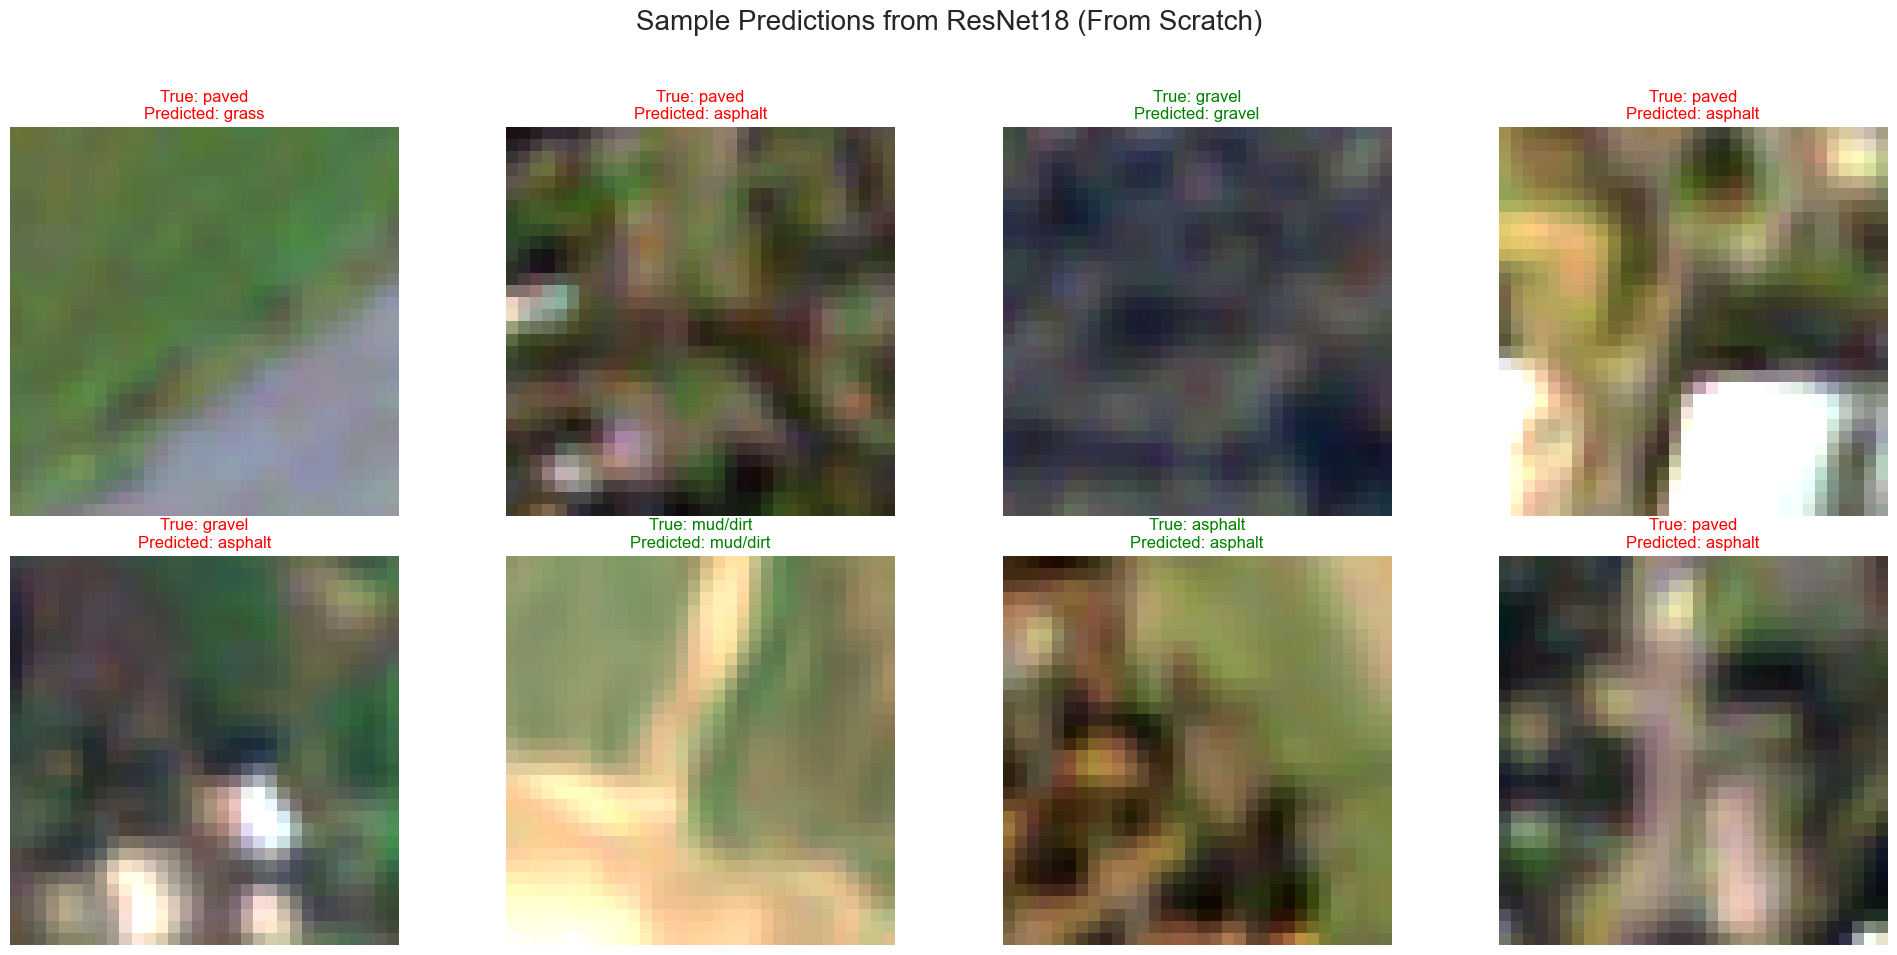

In [10]:
from sqlalchemy import text
# --- Visualize Sample Predictions ---

# Helper function to denormalize images for correct plotting
def denormalize(tensor, means, stds):
    """Denormalizes a tensor image with mean and standard deviation."""
    denorm_tensor = tensor.clone()
    for t, m, s in zip(denorm_tensor, means, stds):
        t.mul_(s).add_(m)
    return denorm_tensor

# (Optional) Customize the model name for the plot title
model_name = "ResNet18 (From Scratch)"

# --- Get a random batch from the validation loader ---
# Note: This uses the 'val_loader' and 'model' variables from the previous evaluation cell
images, labels = next(iter(val_loader))
images_to_device = images.to(device)

# Get model predictions for this batch
outputs = model(images_to_device)
preds = torch.argmax(outputs, 1)

# Inverse mapping from index to class name
idx_to_label = {idx: name for name, idx in global_label_map.items()}

# We only need the means and stds for the first 3 channels (R,G,B) to visualize
vis_means = channel_means[:3]
vis_stds = channel_stds[:3]

# --- Plot 8 random images from the batch ---
plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
plt.suptitle(f'Sample Predictions from {model_name}', fontsize=20)

for i, ax in enumerate(axes.flat):
    if i >= len(images):
        break
    
    # Select the first 3 channels (assumed to be RGB) for visualization
    img_rgb = images[i][:3, :, :]
    
    # Denormalize the image for correct color display
    img_denorm = denormalize(img_rgb, vis_means, vis_stds)
    
    # Transpose from (C, H, W) to (H, W, C) for plotting
    img_display = np.transpose(img_denorm.cpu().numpy(), (1, 2, 0))
    
    # Clip values to [0, 1] to prevent matplotlib warnings
    img_display = np.clip(img_display, 0, 1)

    ax.imshow(img_display)
    
    true_label = idx_to_label[labels[i].item()]
    pred_label = idx_to_label[preds[i].item()]
    
    # Set title color to green for correct predictions, red for incorrect
    title_color = 'green' if true_label == pred_label else 'red'
    
    ax.set_title(f"True: {true_label}\nPredicted: {pred_label}", color=title_color, fontsize=12)
    ax.axis('off')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])

# Save the figure
output_filename = f"sample_predictions_{model_name.lower().replace(' ', '_').replace('(', '').replace(')', '')}.png"
plt.savefig(output_filename, dpi=300)
print(f"Sample predictions plot saved to '{output_filename}'")

plt.show()